# 03 · Random Forest
**Responsable:** Alejandro Flores

La lógica del modelo está en `src/models/random_forest.py` → función `construir_clasificador()`.
Este notebook solo entrena, evalúa, analiza y exporta usando el flujo común
(misma partición, mismo preprocesamiento y mismas métricas que los otros modelos).

In [1]:
# Configuración: permite importar el código común de src/ desde la carpeta notebooks/
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
plt.style.use("ggplot")
sns.set_palette("muted")

from src import config, data, evaluation
from src.training import entrenar_y_evaluar, exportar_final

CLAVE = "rf"

## 1. Datos

In [2]:
df = data.cargar_dataset()
print(df.shape)

(115231, 26)


## 2. Entrenamiento (80%) y evaluación (20%)

In [3]:
pipeline, metricas, (X_test, y_test) = entrenar_y_evaluar(CLAVE, df)
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['url_len','dom_len','tld_len',...,'digit_ratio','spec_ratio','entropy']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [4]:
print(metricas["reporte"])
print({k: round(metricas[k], 4) for k in ("accuracy", "precision", "recall", "f1", "auc")})

              precision    recall  f1-score   support

 Benigna (0)       0.99      0.98      0.99     19729
Phishing (1)       0.89      0.95      0.92      3318

    accuracy                           0.98     23047
   macro avg       0.94      0.96      0.95     23047
weighted avg       0.98      0.98      0.98     23047

{'accuracy': 0.9762, 'precision': 0.8941, 'recall': 0.947, 'f1': 0.9198, 'auc': 0.9935}


## 3. Matriz de confusión

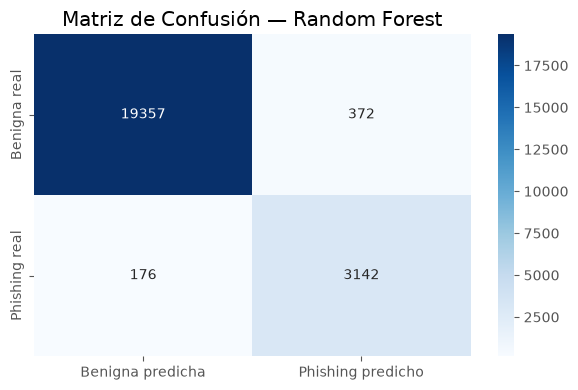

In [5]:
evaluation.graficar_matriz_confusion(metricas, f"Matriz de Confusión — {metricas['modelo']}")
plt.show()

**Interpretación** (conjunto de prueba: 23.047 URLs, 3.318 de phishing):

- **Verdaderos positivos (TP = 3.142):** phishing detectado correctamente. **Recall = 94,7 %**: de cada 100 ataques,
  el modelo detecta casi 95.
- **Falsos negativos (FN = 176):** phishing que se escapó. Es el error más costoso, porque el usuario confiaría en un
  enlace malicioso. Es la cifra más baja de los tres modelos.
- **Falsos positivos (FP = 372):** URLs legítimas marcadas como phishing. **Precision = 89,4 %**: casi 9 de cada 10
  alertas son ataques reales, así que el usuario recibe pocas falsas alarmas.
- **Verdaderos negativos (TN = 19.357):** URLs legítimas reconocidas como tales.

El Random Forest logra a la vez **pocos ataques no detectados y pocas falsas alarmas** (F1 = 0,920).

## 4. Curva ROC

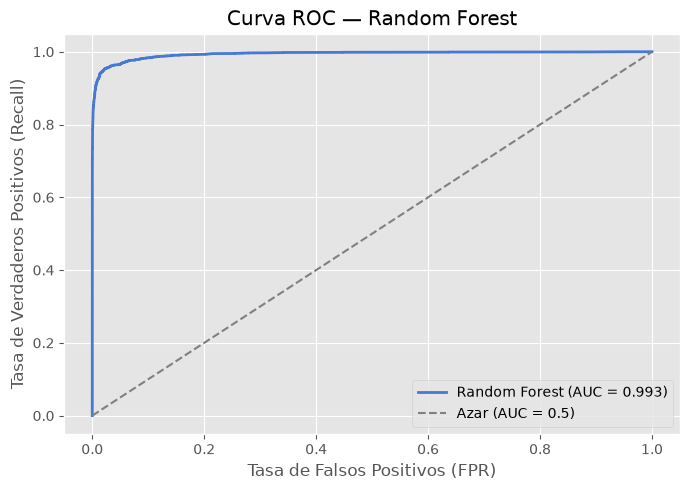

In [6]:
evaluation.graficar_roc({metricas["modelo"]: pipeline}, X_test, y_test, f"Curva ROC — {metricas['modelo']}")
plt.show()

## 5. Importancia de variables
La importancia se mide por la **reducción media de impureza de Gini**: cuánto ayuda cada variable, sumando todos los
árboles, a separar URLs benignas de phishing.

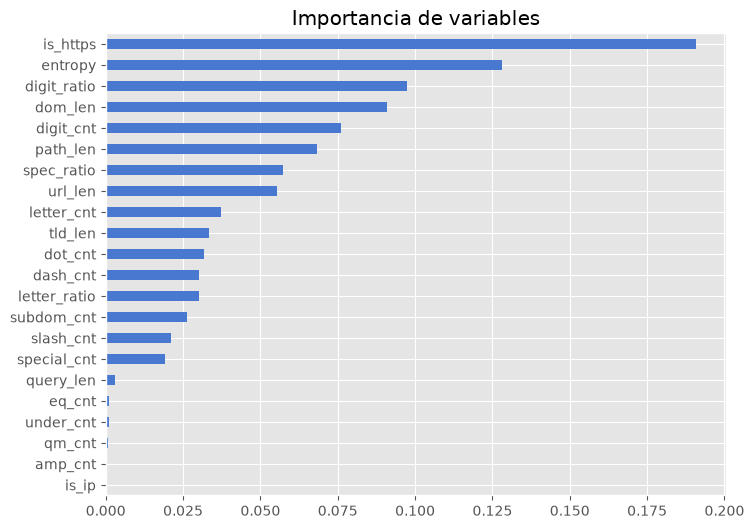

In [7]:
# Importancia de variables (reducción de impureza de Gini)
modelo = pipeline.named_steps["modelo"]
imp = pd.Series(modelo.feature_importances_, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(8, 6), title="Importancia de variables")
plt.show()

**Interpretación:**

- **`is_https` (≈ 19 %)** es la variable más importante, seguida de **`entropy` (≈ 12 %)**, **`digit_ratio` (≈ 10 %)** y
  **`dom_len` (≈ 9 %)**. Coincide con el EDA: eran las variables más correlacionadas con la etiqueta (salvo `dom_len`).
- El peso de `is_https` confirma que en este dataset el **HTTPS no es señal de seguridad**: el 91 % del phishing lo usa.
- `dom_len` gana importancia aquí aunque su correlación lineal era baja (−0,08): el bosque capta relaciones **no
  lineales** y combinaciones entre variables que la correlación no muestra.
- `is_ip`, `amp_cnt`, `qm_cnt`, `under_cnt` y `eq_cnt` casi no aportan: son poco frecuentes (pocas URLs son una IP o
  traen parámetros), así que rara vez sirven para separar las clases.

## 6. Exportación (reentrenado con el 100% de los datos)

In [8]:
ruta = exportar_final(CLAVE, df)
print("Modelo exportado en:", ruta)

Modelo exportado en: models/modelo_rf.pkl


## 7. Conclusiones

- El Random Forest obtiene los **mejores resultados de los tres modelos**: **AUC = 0,993**, Recall = 94,7 %,
  Precision = 89,4 %, F1 = 0,920 y Accuracy = 97,6 %.
- Combina lo más importante en ciberseguridad (pocos ataques no detectados) con pocas falsas alarmas, gracias a que
  capta relaciones no lineales entre las variables.
- **Configuración:** 100 árboles, `class_weight="balanced"` para el desbalance, `max_depth=20` y `min_samples_leaf=2`
  para controlar el sobreajuste y el tamaño del modelo. El `.pkl` exportado (comprimido) pesa ≈ 9 MB, apto para
  GitHub y Render.
- **Desventaja:** es menos interpretable que la Regresión Logística (no hay coeficientes, solo importancias) y más
  pesado. Aun así, es el **candidato a modelo ganador**, que se confirmará en el notebook `05`.